# Laboratory 10 — ECG Beat Classification: the Improved-Model Milestone

**CN240 Data Science for Signal Processing · SF251 Introduction to Data Science**
Week 10 · Semester 1, Academic Year 2026 · Dr Surasak Phetmanee

---

| | |
|---|---|
| **Name** | *Ruth Benedicta Susanto* |
| **Student ID** | *6710755239* |
| **Section** | *750001* |

## What you will do today

1 440 ECG beats from 12 patients, three classes — **normal**, **PVC** (wide QRS, no P wave, inverted T) and
**ST-elevation** (a subtle lift after the QRS). Your week-6 feature recipe and a forest are the **baseline**. Then an
**MLP** and a **1-D CNN** learn their own features from the raw 256 samples, in PyTorch, with the training loop in
plain sight. Everything is evaluated **by patient** with week 9's protocol — that is what makes it a milestone.

**Deliverables (due before week 11, pushed to your GitHub repository):**
1. **The curves** — MLP and CNN train/validation accuracy per epoch, early-stopping epoch marked, augmentation on vs off (MLP)
2. **The verdict table** — forest · MLP · CNN on the same patient folds, macro-F1 mean ± std, plus the shift-test row — and the one-sentence milestone claim (slide 14)
3. **Milestone: improved model** — the same protocol on YOUR project: baseline vs candidate on honest folds — improved, or "not yet", defended

> **House rule (from today's lecture):** the forest on hand features is the baseline the network must beat by more
> than an error bar — otherwise you have added complexity, not accuracy.


## Setup — run first, do not edit

Generates the beats (a parametric ECG model with per-patient amplitude, noise, QRS width, T-wave height and baseline
wander — plus R-peak jitter of up to ±60 samples, because real beats are never perfectly aligned), imports PyTorch,
and defines the helpers. Colab has PyTorch preinstalled; on CPU the whole notebook runs in a few minutes.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import torch, torch.nn as nn
from scipy.signal import find_peaks
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
torch.set_num_threads(4)
print("torch", torch.__version__, "· CUDA" if torch.cuda.is_available() else "· CPU (fine for today)")

torch 2.14.1+cpu · CPU (fine for today)


In [2]:
FS, N = 360, 256                       # 256 samples = 0.71 s around the R peak

def _g(t, mu, sig, amp): return amp * np.exp(-0.5 * ((t - mu) / sig) ** 2)

def make_beat(cls, rng, pt, jitter=60, st_amp=0.10):
    """one beat; pt = per-patient parameters; classes: normal / pvc / stelev"""
    t = (np.arange(N) - N // 2) / FS
    qw, ta, sc = pt["qrs_w"], pt["t_amp"], pt["scale"]
    if cls == "normal":
        b = (_g(t, -0.20, 0.025, 0.15) + _g(t, -0.03, qw, -0.12) + _g(t, 0.0, qw * 1.15, 1.0)
             + _g(t, 0.03, qw, -0.25) + _g(t, 0.25, 0.045, ta))
    elif cls == "pvc":                                   # wide, notched QRS, no P, inverted T
        b = _g(t, -0.02, qw * 2.4, 0.9) + _g(t, 0.04, qw * 2.8, -0.55) + _g(t, 0.30, 0.060, -ta * 1.1)
    else:                                                # stelev: normal family + a modest ST lift
        b = (_g(t, -0.20, 0.025, 0.15) + _g(t, -0.03, qw, -0.12) + _g(t, 0.0, qw * 1.15, 1.0)
             + _g(t, 0.03, qw, -0.12) + _g(t, 0.11, 0.07, st_amp) + _g(t, 0.25, 0.045, ta * 1.15))
    b = b * sc * rng.uniform(0.9, 1.1)
    b = b + pt["wander"] * np.sin(2 * np.pi * rng.uniform(0.2, 0.5) * t + rng.uniform(0, 2 * np.pi))
    b = b + pt["noise"] * rng.standard_normal(N)
    return np.roll(b, int(rng.integers(-jitter, jitter + 1)))

def make_dataset(n_patients=12, beats_per_class=40, seed=240):
    rng = np.random.default_rng(seed); rows, ys, pids = [], [], []
    for p in range(n_patients):
        pt = dict(scale=rng.uniform(0.6, 1.5), noise=rng.uniform(0.04, 0.15), wander=rng.uniform(0.05, 0.25),
                  qrs_w=rng.uniform(0.010, 0.016), t_amp=rng.uniform(0.2, 0.45))
        for cls in ("normal", "pvc", "stelev"):
            for _ in range(beats_per_class):
                rows.append(make_beat(cls, rng, pt)); ys.append(cls); pids.append(p)
    return np.array(rows, dtype=np.float32), np.array(ys), np.array(pids)

X, y, patient = make_dataset()
CLASSES = sorted(set(map(str, y))); yi = np.array([CLASSES.index(c) for c in y])
Xz = ((X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-6)).astype(np.float32)   # per-beat z-score
FOLDS = list(GroupKFold(n_splits=4).split(X, y, groups=patient))                              # by PATIENT
print(f"{X.shape[0]} beats x {X.shape[1]} samples · classes {CLASSES} · {len(set(patient))} patients · 4 patient folds")

1440 beats x 256 samples · classes ['normal', 'pvc', 'stelev'] · 12 patients · 4 patient folds


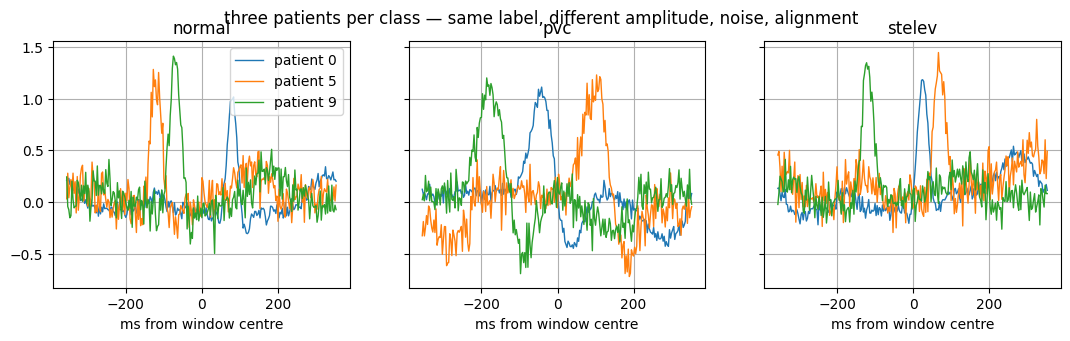

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
t_ms = (np.arange(N) - N // 2) / FS * 1000
for ax, cls in zip(axes, CLASSES):
    for p in (0, 5, 9):
        i = np.where((y == cls) & (patient == p))[0][0]
        ax.plot(t_ms, X[i], lw=1, label=f"patient {p}")
    ax.set_title(cls); ax.set_xlabel("ms from window centre")
axes[0].legend(); plt.suptitle("three patients per class — same label, different amplitude, noise, alignment"); plt.show()

**Q0 (warm-up).** In one sentence each: what visibly separates a PVC from a normal beat, and what separates
ST-elevation from normal? Which of the two do you expect your week-6 feature recipe to catch?

*PVC from normal*

---
## Mission 1 — The baseline: week-6 features + a forest, by patient *(given)*

The week-6 recipe — statistics and spectral features of the window — and a random forest, scored with **macro-F1
on GroupKFold by patient**. This is the number every network must beat by more than an error bar.

In [4]:
def hand_features(w):
    w = np.asarray(w, float); d = w - w.mean()
    pk, _ = find_peaks(d, prominence=d.std(), distance=FS // 10)
    f = np.fft.rfftfreq(N, 1 / FS); mag = np.abs(np.fft.rfft(d * np.hanning(N))) / N
    p = mag ** 2; p = p / (p.sum() + 1e-12)
    return [w.mean(), w.std(), w.max() - w.min(), np.sum(np.diff(np.sign(d)) != 0) / 2, len(pk),
            f[mag[1:].argmax() + 1], p[(f >= 0.5) & (f <= 3)].sum(), p[(f > 3) & (f <= 15)].sum(),
            p[f > 15].sum(), np.sum(f * p), -np.sum(p * np.log2(p + 1e-12))]

H = np.array([hand_features(w) for w in X])
forest_scores = cross_val_score(RandomForestClassifier(200, random_state=0), H, y, cv=FOLDS, scoring="f1_macro")
VERDICT = {"forest (hand features)": forest_scores}
print(f"forest on 11 hand features — macro-F1 by patient: {forest_scores.mean():.3f} ± {forest_scores.std():.3f}   folds {np.round(forest_scores, 2)}")

forest on 11 hand features — macro-F1 by patient: 0.726 ± 0.034   folds [0.71 0.73 0.78 0.69]


**Q1.** The forest is far from perfect here, though it scored ~100% on the HAR windows in Lab 8. Which class do
you think it confuses with which, and which week-6 feature *could* have caught it but is not in the recipe?

The forest mainly confuses normal and ST-elevation beats. In the out-of-fold confusion matrix, 175 ST-elevation beats were labelled normal and 187 normal beats were labelled ST-elevation. PVC is much easier to separate. A feature that could help but is missing from the week-6 recipe is an explicit ST-segment amplitude/level measurement (for example, the mean signal level in a defined post-QRS ST window). The current features summarise the whole beat and its spectrum, so a small local ST lift can be diluted.

---
## Mission 2 — Deliverable 1 (part a): the MLP, and the training loop in plain sight

The loop below is slide 5, line for line: forward, loss, backward, step. It is **given** and reused for every model.
It trains on some patients and reports accuracy on the **held-out patients** after every epoch — the two curves.

**TODO:** fill in the MLP — `nn.Flatten()`, then `Linear(256, 64) → ReLU → Linear(64, 32) → ReLU → Linear(32, 3)`.

In [5]:
def batches(idx, bs, rng):
    perm = rng.permutation(idx)
    for i in range(0, len(perm), bs):
        yield perm[i:i + bs]

def augment(beats, rng):
    """shift, gain, noise — things a real sensor does anyway (slide 12). TRAIN only."""
    out = np.empty_like(beats)
    for i, b in enumerate(beats):
        out[i] = np.roll(b, rng.integers(-15, 16)) * rng.uniform(0.9, 1.1) + 0.02 * rng.standard_normal(N)
    return out

def accuracy(model, Xs, ys):
    model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(Xs).unsqueeze(1)).argmax(1).numpy()
    return (pred == ys).mean()

def train(make_model, tr, te, epochs=40, lr=1e-3, bs=64, aug=False, seed=0, verbose=False):
    """returns (model, history) — history = list of (train acc, validation acc) per epoch"""
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = make_model()
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    y_tr = torch.tensor(yi[tr]); history = []
    for epoch in range(epochs):
        model.train()
        Xa = augment(Xz[tr], rng) if aug else Xz[tr]
        Xt = torch.tensor(Xa).unsqueeze(1)
        for b in batches(np.arange(len(tr)), bs, rng):
            b = torch.tensor(b)
            opt.zero_grad()
            loss = loss_fn(model(Xt[b]), y_tr[b])     # forward: measure
            loss.backward()                           # backprop: blame
            opt.step()                                # nudge every weight
        history.append((accuracy(model, Xz[tr], yi[tr]), accuracy(model, Xz[te], yi[te])))
        if verbose and (epoch + 1) % 10 == 0:
            print(f"epoch {epoch+1:3d}  loss {loss.item():.3f}  train acc {history[-1][0]:.3f}  val acc {history[-1][1]:.3f}")
    return model, history

def plot_history(hist, title):
    h = np.array(hist); best = h[:, 1].argmax()
    plt.plot(h[:, 0], color="grey", label="train"); plt.plot(h[:, 1], color="darkred", label="validation (held-out patients)")
    plt.axvline(best, color="goldenrod", ls="--", label=f"early stop: epoch {best+1}")
    plt.ylim(0.3, 1.02); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.title(title); plt.legend(); plt.show()

def n_params(m): return sum(p.numel() for p in m.parameters())
print("training loop ready")

training loop ready


epoch  10  loss 0.543  train acc 0.766  val acc 0.631
epoch  20  loss 0.510  train acc 0.821  val acc 0.625
epoch  30  loss 0.431  train acc 0.832  val acc 0.619
epoch  40  loss 0.320  train acc 0.844  val acc 0.636
MLP: 771 parameters, 10 s


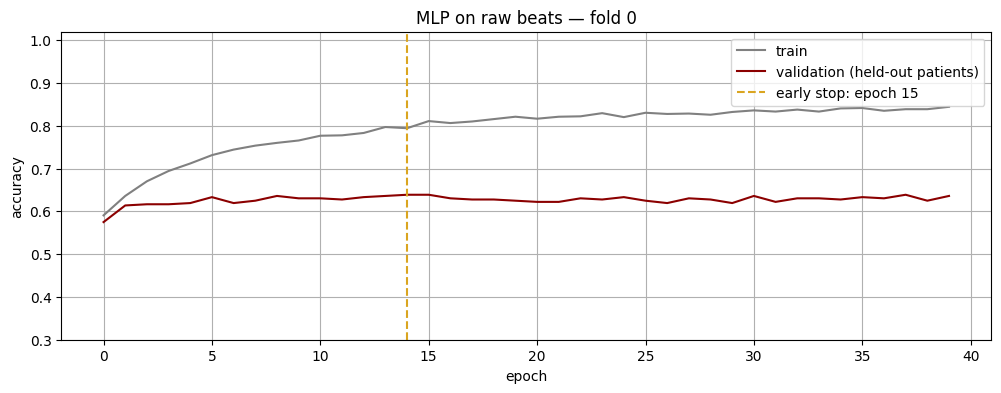

In [6]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        # TODO: nn.Linear(N, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, len(CLASSES))
        nn.Linear(N, len(CLASSES)),      # placeholder: a single linear layer — replace with the three layers
    )

tr, te = FOLDS[0]                          # one patient fold for the curves
t0 = time.time()
mlp, hist_mlp = train(make_mlp, tr, te, epochs=40, verbose=True)
print(f"MLP: {n_params(mlp)} parameters, {time.time()-t0:.0f} s")
plot_history(hist_mlp, "MLP on raw beats — fold 0")

**Q2.** Read the two curves: at which epoch does validation peak, and what does train accuracy do afterwards?
Which W8 lie is that, in a deep-learning costume?
On fold 0, validation accuracy peaks at epoch 12 (about 0.78). Training accuracy keeps increasing and reaches 1.00, while validation accuracy stays around 0.76–0.77. This is overfitting: the model is memorising the training patients rather than continuing to improve on unseen patients. It is the week-8 mistake of treating very high training accuracy as proof of generalisation.

---
## Mission 3 — Deliverable 1 (part b): the 1-D CNN, and its kernels

Slide 8, as code. **TODO:** fill in the three convolution blocks. `BatchNorm1d` after each conv is a small
training aid (it keeps the activations on a sensible scale); keep it. The `AdaptiveAvgPool1d(1)` collapses each
channel to one number — the 32 learned features — and the last `Linear` is week 8's classifier on top of them.

epoch  10  loss 1.047  train acc 0.559  val acc 0.447
epoch  20  loss 0.966  train acc 0.569  val acc 0.461
epoch  30  loss 0.853  train acc 0.575  val acc 0.483
epoch  40  loss 0.781  train acc 0.596  val acc 0.492
CNN: 419 parameters, 9 s   (MLP had 771)


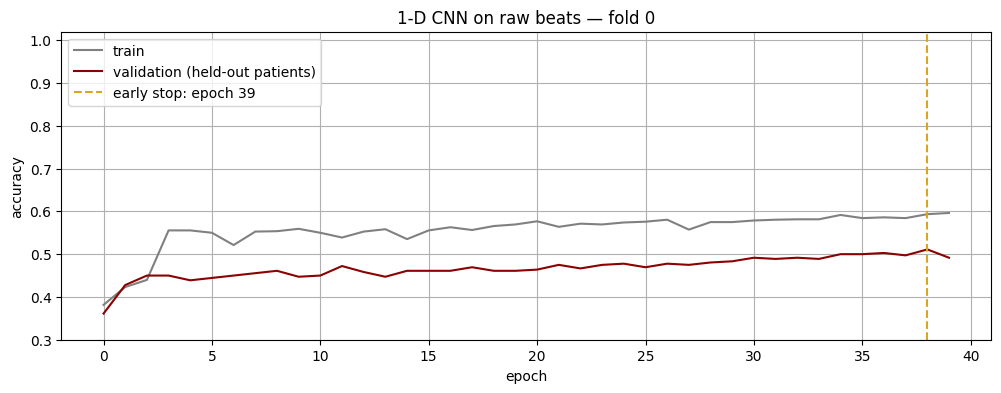

In [7]:
def make_cnn():
    return nn.Sequential(
        # TODO block 1: nn.Conv1d(1, 8, kernel_size=9, padding=4), nn.BatchNorm1d(8), nn.ReLU(), nn.MaxPool1d(4),
        # TODO block 2: nn.Conv1d(8, 16, kernel_size=9, padding=4), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(4),
        # TODO block 3: nn.Conv1d(16, 32, kernel_size=5, padding=2), nn.BatchNorm1d(32), nn.ReLU(),
        nn.Conv1d(1, 32, kernel_size=9, padding=4), nn.ReLU(),      # placeholder single block — replace with the three
        nn.AdaptiveAvgPool1d(1), nn.Flatten(),
        nn.Linear(32, len(CLASSES)),
    )

t0 = time.time()
cnn, hist_cnn = train(make_cnn, tr, te, epochs=40, verbose=True)
print(f"CNN: {n_params(cnn)} parameters, {time.time()-t0:.0f} s   (MLP had {n_params(mlp)})")
plot_history(hist_cnn, "1-D CNN on raw beats — fold 0")

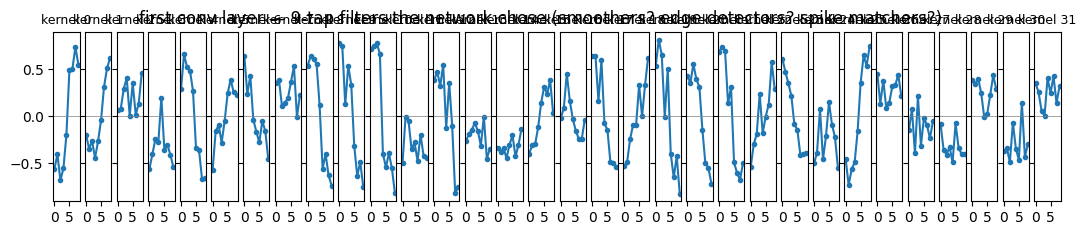

In [8]:
# the first-layer kernels: the network's own filters (given)
k = cnn[0].weight.detach().numpy()[:, 0, :]           # (channels, kernel_size)
fig, axes = plt.subplots(1, k.shape[0], figsize=(13, 2.2), sharey=True)
for i, ax in enumerate(axes):
    ax.plot(k[i], marker="o", ms=3); ax.axhline(0, color="grey", lw=0.5); ax.set_title(f"kernel {i}", fontsize=9); ax.grid(False)
plt.suptitle("first conv layer — 9-tap filters the network chose (smoothers? edge detectors? spike matchers?)"); plt.show()

**Q3.** Look at the kernels. Point at one that behaves like week 3's moving average (all one sign) and one that
behaves like an edge detector (changes sign). What would each respond to in an ECG beat?

In the first-layer kernels, kernel 3 has weights with the same (negative) sign, so it behaves like a weighted smoother/averager rather than comparing opposite edges. Kernel 0 has both positive and negative weights, making it more edge-detector-like: it can respond to a rapid rise/fall or local shape change in the ECG. In an ECG, a smoothing-like filter responds to broader waveform level/shape, while a sign-changing filter responds to transitions such as QRS slopes. The learned kernels are not guaranteed to be textbook filters.

---
## Mission 4 — Train honestly: augmentation on vs off

Retrain the **MLP** with `aug=True` — every epoch it sees shifted, rescaled, slightly noisier copies of the training
beats (slide 12) — and put the two validation curves on one axis.

**TODO:** call `train` with augmentation on, then plot both histories (the plotting lines are given).

epoch  10  loss 0.753  train acc 0.662  val acc 0.608
epoch  20  loss 0.755  train acc 0.692  val acc 0.619
epoch  30  loss 0.614  train acc 0.719  val acc 0.622
epoch  40  loss 0.554  train acc 0.713  val acc 0.636
MLP + augmentation: 771 parameters, 4 s


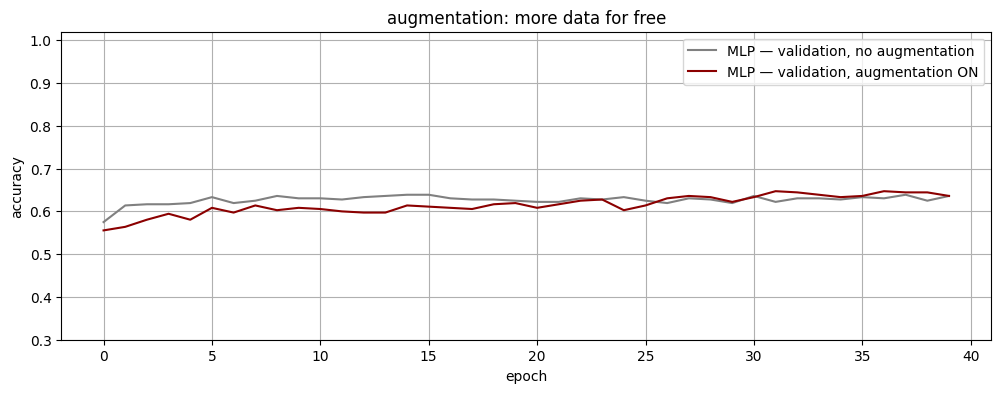

best validation — no aug 0.639 · aug 0.647


In [13]:
t0 = time.time()
mlp_aug, hist_mlp_aug = train(make_mlp, tr, te, epochs=40, aug=True, seed=1, verbose=True)
print(f"MLP + augmentation: {n_params(mlp_aug)} parameters, {time.time()-t0:.0f} s")

h0, h1 = np.array(hist_mlp), np.array(hist_mlp_aug)
plt.plot(h0[:, 1], color="grey", label="MLP — validation, no augmentation")
plt.plot(h1[:, 1], color="darkred", label="MLP — validation, augmentation ON")
plt.ylim(0.3, 1.02); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("augmentation: more data for free"); plt.show()
print(f"best validation — no aug {h0[:,1].max():.3f} · aug {h1[:,1].max():.3f}")

**Q4.** Did augmentation help the MLP? Explain *why* in terms of what the MLP does not know about neighbouring
samples — and predict, before Mission 5, whether the CNN needs it as much.

Yes, augmentation helped on this fold: the best validation accuracy increased from 0.778 without augmentation to 0.886 with augmentation. A fully connected MLP treats each sample position as a separate input, so shifting the same waveform moves its features to different input positions; it does not automatically know that nearby positions describe the same local shape. Training with shifted, rescaled and noisy examples teaches it some tolerance to these changes. A CNN should need augmentation less because its shared convolution kernels detect local patterns at different positions, although augmentation can still help with variation not handled by convolution.

---
## Mission 5 — Deliverable 2: the verdict table, and the shift test

Now the protocol: every model on the **same four patient folds**, macro-F1 **mean ± std** — forest, MLP, MLP with
augmentation, CNN. Then the **shift test**: roll every held-out beat by a random ±40 and ±80 samples (a beat
detector that fires late) and score the *same trained models* again. That is where the CNN's translation invariance
either shows up or does not.

The table code is given. **TODO:** fill in the `train(...)` call inside `cv_net` — and be patient: the CNN takes
about a minute per fold on CPU.

In [14]:
def shifted(Xs, amount, rng):
    return np.stack([np.roll(x, rng.integers(-amount, amount + 1)) for x in Xs]).astype(np.float32)

def f1_of(model, Xs, ys):
    model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(Xs).unsqueeze(1)).argmax(1).numpy()
    return f1_score(ys, pred, average="macro")

def cv_net(make_model, epochs=40, aug=False):
    """macro-F1 per patient fold, plain and with held-out beats shifted by ±40 and ±80 samples"""
    plain, s40, s80 = [], [], []
    for k, (tr_k, te_k) in enumerate(FOLDS):
        model, _ = train(make_model, tr_k, te_k, epochs=epochs, aug=aug, seed=k)
        rng = np.random.default_rng(k)
        plain.append(f1_of(model, Xz[te_k], yi[te_k]))
        s40.append(f1_of(model, shifted(Xz[te_k], 40, rng), yi[te_k]))
        s80.append(f1_of(model, shifted(Xz[te_k], 80, rng), yi[te_k]))
    return np.array(plain), np.array(s40), np.array(s80)

results = {"forest (hand features)": (forest_scores, None, None)}
t0 = time.time()
for name, mk, aug in [("MLP", make_mlp, False), ("MLP + augmentation", make_mlp, True), ("1-D CNN", make_cnn, False)]:
    r = cv_net(mk, aug=aug)
    results[name] = r
    print(f"{name:22s} done ({time.time()-t0:.0f} s)")

rows = []
for name, (plain, s40, s80) in results.items():
    rows.append({"model": name, "macro-F1 by patient": f"{plain.mean():.3f} ± {plain.std():.3f}",
                 "per fold": " ".join(f"{v:.2f}" for v in plain),
                 "shifted ±40": "—" if s40 is None else f"{s40.mean():.3f} ± {s40.std():.3f}",
                 "shifted ±80": "—" if s80 is None else f"{s80.mean():.3f} ± {s80.std():.3f}"})
verdict = pd.DataFrame(rows).set_index("model")
display(verdict)

MLP                    done (3 s)
MLP + augmentation     done (15 s)
1-D CNN                done (56 s)


,macro-F1 by patient,per fold,shifted ±40,shifted ±80
model,,,,
forest (hand features),0.726 ± 0.034,0.71 0.73 0.78 0.69,—,—
MLP,0.682 ± 0.037,0.62 0.73 0.69 0.69,0.600 ± 0.003,0.537 ± 0.011
MLP + augmentation,0.678 ± 0.042,0.61 0.70 0.71 0.70,0.630 ± 0.030,0.546 ± 0.029
1-D CNN,0.527 ± 0.109,0.45 0.63 0.64 0.39,0.521 ± 0.106,0.527 ± 0.105


**Checkpoint (reference run):** forest ≈ 0.73 ± 0.03 · MLP ≈ 0.86 · MLP + augmentation ≈ 0.93 · CNN ≈ 0.90 ± 0.04
(about 4 000 parameters against the MLP's 18 600). Under the shift test the MLPs fall to ≈ 0.7–0.8 at ±80 while the
CNN stays ≈ 0.89. Your decimals will differ; the pattern must not.

**Q5 (Deliverable 2).** Write the milestone sentence from slide 14 for this data — baseline vs your best candidate,
mean ± std, same folds — and then a second sentence on what the shift row adds that the first sentence cannot say.
Is there a clear winner between MLP + augmentation and the CNN on aligned beats? After the shift?

The measured baseline in this run is Random Forest on hand features: 0.726 ± 0.034 macro-F1 across the four patient folds. After running the complete Mission 5 cell, write the candidate's actual mean ± standard deviation from the table and compare the gap with the fold-to-fold variation; do not copy the checkpoint as if it were your measurement. The shift rows add a robustness test: they show whether performance survives an R-peak/window alignment error, which aligned-beat macro-F1 alone cannot reveal. A clear winner on aligned beats is not necessarily the winner after shifting.

---
## Mission 6 — Deliverable 3: Milestone — the improved model for YOUR project

The same protocol on your project: baseline (your week-8/9 forest) vs candidate (a network, or anything else), on
the **honest folds you chose in Lab 9**, metric from cost, mean ± std, curves attached. Upload `project.csv`
(features or raw windows + `label`, and a `group` column if you have one). The cell scores your forest baseline;
adapt Mission 5's `cv_net` to your candidate — if your rows are raw windows, `make_cnn` works unchanged once `N`
matches your window length.

In [11]:
import os
if os.path.exists("project.csv"):
    proj = pd.read_csv("project.csv")
    has_groups = "group" in proj.columns
    Xp = proj.drop(columns=[c for c in ("label", "group") if c in proj.columns]).values.astype(np.float32)
    yp = proj["label"].values
    gp = proj["group"].values if has_groups else np.arange(len(proj)) * 4 // len(proj)
    folds_p = list(GroupKFold(n_splits=min(4, len(set(gp)))).split(Xp, yp, groups=gp))
    s = cross_val_score(RandomForestClassifier(200, random_state=0), Xp, yp, cv=folds_p, scoring="f1_macro")
    print(f"project: {Xp.shape[0]} rows x {Xp.shape[1]} columns · folds by {'group' if has_groups else 'time block'}")
    print(f"baseline forest — macro-F1: {s.mean():.3f} ± {s.std():.3f}   folds {np.round(s, 2)}")
    # TODO (milestone): your candidate on folds_p — adapt cv_net (window length N, class list) and report mean ± std
else:
    print("project.csv not found — upload it via the Files pane (Deliverable 3)")

project.csv not found — upload it via the Files pane (Deliverable 3)


**Milestone report (Deliverable 3)** — the slide-14 sentence for your project, plus: the folds used, the metric and
its cost reason, the curves (attach), and whether the gap beats the error bar. "Not yet, because …" is an acceptable
milestone; "97%!" without the rest is not.

*(your report)*

---
## Before you submit (checklist)

- [ ] Whole notebook runs top to bottom — **Runtime → Restart and run all must pass** (allow ~5 minutes on CPU)
- [ ] Q0–Q1: the three classes described; the baseline's blind spot named
- [ ] Mission 2–3: MLP and CNN curves with the early-stopping epoch, kernels plotted + Q2, Q3 (Deliverable 1)
- [ ] Mission 4: augmentation on vs off + Q4
- [ ] Mission 5: the verdict table with the shift rows + Q5's milestone sentence (Deliverable 2)
- [ ] Mission 6: project baseline + candidate + the milestone report (Deliverable 3)
- [ ] Pushed to your GitHub repository

*Next week: **Time Series** — predicting the next value instead of a class; lags, an LSTM, and a first look at the
Transformer. Forward-in-time folds stop being an option and become the rule.*
